In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from modules import data_loader, metrics, learning, plotting, utils, params, pipelines
from models.gmp import GMP
import matplotlib.pyplot as plt
import numpy as np
import torch
import pandas as pd

Load data from files and init acpr meter

In [3]:
M = 5

dataset_path = "datasets/Custom_dataset"
# dataset_path = "datasets/signal_samples_newPA_vo_filter_no_atten_-11_dBm"

container = data_loader.DataContainer()
container.load_data(file_path=dataset_path)
container.cut_signals(M)
container.get_gained_signals()
print(f"gain: {container.gain}")

acpr_meter = metrics.ACPR(
        sample_rate=container.input_signal_fs,
        main_measurement_bandwidth=container.bw_main_ch,
        adjacent_channel_offset=[-container.sub_ch, container.sub_ch],
        segment_length=container.nperseg,
        overlap_percentage=60,
        window='blackmanharris',
        fft_length=container.nperseg,
        power_units='dBW',
        return_main_power=True,
        return_adjacent_powers=True
    )

# container.train_output = container.train_output / container.gain
# container.val_output = container.val_output / container.gain

gain: 7.750391483306885


In [ ]:
frame_length = 64
batch_size = 128
batch_size_eval = 2048

pa_train_loader, pa_val_loader, pa_input_norm, pa_target_norm = data_loader.build_dataloaders(container,
                                                                                              frame_length=frame_length,
                                                                                              batch_size=batch_size,
                                                                                              batch_size_eval=batch_size_eval,
                                                                                              arch="pa",
                                                                                              normalize_method=None)
dla_train_loader, dla_val_loader, dla_input_norm, dla_target_norm = data_loader.build_dataloaders(container,
                                                                                                  frame_length=frame_length,
                                                                                                  batch_size=batch_size,
                                                                                                  batch_size_eval=batch_size_eval,
                                                                                                  arch="dla",
                                                                                                  normalize_method=None)
ila_train_loader, ila_val_loader, ila_input_norm, ila_target_norm = data_loader.build_dataloaders(container,
                                                                                                  frame_length=frame_length,
                                                                                                  batch_size=batch_size,
                                                                                                  batch_size_eval=batch_size_eval,
                                                                                                  arch="ila",
                                                                                                  normalize_method=None)

criterion = metrics.compute_mse
metric_criterion = metrics.compute_nmse


In [18]:
from modules import utils
from models.base_model import BaseModel


class NewGMP(BaseModel, torch.nn.Module):
    """
    Generalized Memory Polynomial with complex numbers stored as [..., 2]:
        [..., 0] = real
        [..., 1] = imaginary

    Input:
        x: [B, T, 2]

    Output:
        y: [B, T, 2]

    Coefficients:
        a: [Ka, La, 2]
        b: [Kb, Lb, Mb, 2]
        c: [Kc, Lc, Mc, 2]

    GMP:

        y[n] =
            sum_{k=0}^{Ka-1} sum_{l=0}^{La-1}
                a[k,l] * x[n-l] * |x[n-l]|^k

            + sum_{k=1}^{Kb} sum_{l=0}^{Lb-1} sum_{m=1}^{Mb}
                b[k,l,m] * x[n-l] * |x[n-l-m]|^k

            + sum_{k=1}^{Kc} sum_{l=0}^{Lc-1} sum_{m=1}^{Mc}
                c[k,l,m] * x[n-l] * |x[n-l+m]|^k
    """

    def __init__(self,
                 Ka: int,
                 La: int,
                 Kb: int,
                 Lb: int,
                 Mb: int,
                 Kc: int,
                 Lc: int,
                 Mc: int,
                 model_name: str = ""):

        torch.nn.Module.__init__(self)
        BaseModel.__init__(self, model_name=model_name)

        self.Ka, self.La = Ka, La
        self.Kb, self.Lb, self.Mb = Kb, Lb, Mb
        self.Kc, self.Lc, self.Mc = Kc, Lc, Mc

        self.a = torch.nn.Parameter(0.01 * torch.randn((Ka, La, 2), dtype=torch.float32))
        self.b = torch.nn.Parameter(0.01 * torch.randn((Kb, Lb, Mb, 2), dtype=torch.float32))
        self.c = torch.nn.Parameter(0.01 * torch.randn((Kc, Lc, Mc, 2), dtype=torch.float32))

        self.register_buffer('powers_Ka', torch.arange(Ka, dtype=torch.int32))
        self.register_buffer('powers_Kb', torch.arange(1, Kb + 1, dtype=torch.int32))
        self.register_buffer('powers_Kc', torch.arange(1, Kc + 1, dtype=torch.int32))
        self.register_buffer('arange_La', torch.arange(La, dtype=torch.int32))
        self.register_buffer('arange_Lb', torch.arange(Lb, dtype=torch.int32))
        self.register_buffer('arange_Lc', torch.arange(Lc, dtype=torch.int32))
        self.register_buffer('arange_Mb', torch.arange(1, Mb + 1, dtype=torch.int32))
        self.register_buffer('arange_Mc', torch.arange(1, Mc + 1, dtype=torch.int32))

        self.left_pad = max(self.La, self.Lb + self.Mb, self.Lc)
        self.right_pad = self.Mc

    @staticmethod
    def complex_mul(a, x):
        """
        Complex multiplication for [..., 2] representation.

        a = [a_re, a_im]
        x = [x_re, x_im]

        result = a * x
              = [a_re*x_re - a_im*x_im,
                 a_re*x_im + a_im*x_re]
        """

        a_re = a[..., 0]
        a_im = a[..., 1]

        x_re = x[..., 0]
        x_im = x[..., 1]

        y_re = a_re * x_re - a_im * x_im
        y_im = a_re * x_im + a_im * x_re

        return torch.stack((y_re, y_im),dim=-1)

    def _get_filename(self):
        return (
            f"{self.model_name}_{self.class_name}_"
            f"Ka{self.Ka}_La{self.La}_"
            f"Kb{self.Kb}_Lb{self.Lb}_Mb{self.Mb}_"
            f"Kc{self.Kc}_Lc{self.Lc}_Mc{self.Mc}.pt"
        )

    def forward(self, x):

        B, T, _ = x.shape

        t_range = torch.arange(T,device=x.device)

        x_pad = torch.zeros(B, T + self.left_pad + self.right_pad, 2, dtype=x.dtype, device=x.device)

        x_pad[:, self.left_pad:self.left_pad + T] = x

        # |x[n]|
        abs_x = torch.sqrt(x_pad.pow(2).sum(dim=-1, keepdim=True))

        y = torch.zeros_like(x)

        for n in t_range:

            out = torch.zeros(B, 2, dtype=x.dtype, device=x.device)

            # ALIGNED TERMS

            for k in self.powers_Ka:

                for l in self.arange_La:

                    idx = (n - l + self.left_pad)

                    xn = x_pad[:, idx]

                    abs_xn = abs_x[:, idx]

                    term = self.complex_mul(self.a[k, l],xn)

                    term = term * (abs_xn ** k)

                    out += term

            # LAGGING ENVELOPE TERMS

            for k in self.powers_Kb:
                for l in self.arange_Lb:
                    for m in self.arange_Mb:

                        signal_idx = (n - l + self.left_pad)

                        envelope_idx = (n - l - m + self.left_pad)

                        xn = x_pad[:, signal_idx]

                        abs_xn_m = abs_x[:, envelope_idx]

                        term = self.complex_mul(self.b[k - 1, l, m - 1], xn)

                        term = term * (abs_xn_m ** k)

                        out += term

            # LEADING ENVELOPE TERMS

            for k in self.powers_Kc:
                for l in self.arange_Lc:
                    for m in self.arange_Mc:

                        signal_idx = (n - l + self.left_pad)

                        envelope_idx = (n - l + m + self.left_pad)

                        xn = x_pad[:, signal_idx]

                        abs_xn_p = abs_x[:, envelope_idx]

                        term = self.complex_mul(self.c[k - 1, l, m - 1], xn)

                        term = term * (abs_xn_p ** k)

                        out += term

            y[:, n] = out

        return y

In [19]:
pa_degree = 2
pa_config = params.make_gmp_params(
    Ka=pa_degree,
    La=pa_degree,
    Kb=pa_degree,
    Lb=pa_degree,
    Mb=pa_degree,
    Kc=pa_degree,
    Lc=pa_degree,
    Mc=pa_degree,
)

pa_model = NewGMP(**pa_config, model_name="pa")


print(f"total_params: {pa_model.count_params()}")

epochs = 150
lr = 0.01

optimizer = torch.optim.AdamW(pa_model.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

if not pa_model.load_weights():
      learning.train(net=pa_model,
            criterion=criterion,
            optimizer=optimizer,
            train_loader=pa_train_loader,
            val_loader=pa_val_loader,
            n_epochs=epochs,
            metric_criterion=metric_criterion,
            scheduler=scheduler)
      pa_model.save_weights()
utils.freeze_model(pa_model)


y_val_pa = learning.net_inference(net=pa_model, x=container.val_input_orig)
pa_nmse = metrics.compute_nmse(y_val_pa, container.val_output)
print(f"Model NMSE: {pa_nmse:.2f}")

total_params: 40
No saved weights found at model_params/pa_NewGMP_Ka2_La2_Kb2_Lb2_Mb2_Kc2_Lc2_Mc2.pt, initializing new parameters.
===Start training===
Epoch 0000 — train_loss: 0.03163978, val_loss: 0.01061892, val_NMSE: -7.35, lr: 0.01


KeyboardInterrupt: 

PA model

In [7]:
pa_degree = 2
pa_config = params.make_gmp_params(
    Ka=pa_degree,
    La=pa_degree,
    Kb=pa_degree,
    Lb=pa_degree,
    Mb=pa_degree,
    Kc=pa_degree,
    Lc=pa_degree,
    Mc=pa_degree,
)

pa_model = GMP(**pa_config, model_name="pa")


print(f"total_params: {pa_model.count_params()}")

# epochs = 150
# lr = 0.001


epochs = 50
lr = 0.1

optimizer = torch.optim.AdamW(pa_model.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

if not pa_model.load_weights():
      learning.train(net=pa_model,
            criterion=criterion,
            optimizer=optimizer,
            train_loader=pa_train_loader,
            val_loader=pa_val_loader,
            n_epochs=epochs,
            metric_criterion=metric_criterion,
            scheduler=scheduler)
      pa_model.save_weights()
utils.freeze_model(pa_model)


y_val_pa = learning.net_inference(net=pa_model, x=container.val_input)
pa_nmse = metrics.compute_nmse(y_val_pa, container.val_output)
print(f"Model NMSE: {pa_nmse:.2f}")

total_params: 40
No saved weights found at model_params/pa_GMP_Ka2_La2_Kb2_Lb2_Mb2_Kc2_Lc2_Mc2.pt, initializing new parameters.
===Start training===
Epoch 0000 — train_loss: 0.00142706, val_loss: 0.00012888, val_NMSE: -26.51, lr: 0.1
Epoch 0001 — train_loss: 0.00012512, val_loss: 0.00006968, val_NMSE: -29.18, lr: 0.1
Epoch 0002 — train_loss: 0.00009666, val_loss: 0.00005899, val_NMSE: -29.90, lr: 0.1
Epoch 0003 — train_loss: 0.00008943, val_loss: 0.00005387, val_NMSE: -30.30, lr: 0.1
Epoch 0004 — train_loss: 0.00008623, val_loss: 0.00005414, val_NMSE: -30.27, lr: 0.1
Epoch 0005 — train_loss: 0.00008431, val_loss: 0.00004963, val_NMSE: -30.65, lr: 0.1
Epoch 0006 — train_loss: 0.00008194, val_loss: 0.00004793, val_NMSE: -30.80, lr: 0.1
Epoch 0007 — train_loss: 0.00008136, val_loss: 0.00004728, val_NMSE: -30.86, lr: 0.1
Epoch 0008 — train_loss: 0.00008054, val_loss: 0.00004654, val_NMSE: -30.93, lr: 0.1
Epoch 0009 — train_loss: 0.00008012, val_loss: 0.00004712, val_NMSE: -30.88, lr: 0.1
E

In [13]:
with torch.autograd.profiler.profile(use_cuda=False) as prof:
    with torch.no_grad():
        output = pa_model.forward(container.val_input)

print(prof.key_averages().table(sort_by="cpu_time_total", row_limit=20))

-------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                     Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
-------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                aten::pow        21.32%       1.702ms        21.97%       1.754ms     194.933us             9  
                aten::mul        21.16%       1.690ms        21.16%       1.690ms     563.200us             3  
              aten::copy_        13.20%       1.054ms        13.20%       1.054ms      87.850us            12  
                 aten::to         0.41%      32.800us        11.36%     907.100us      45.355us            20  
           aten::_to_copy         0.78%      62.000us        10.95%     874.300us      97.144us             9  
             aten::gather        10.77%     860.000us        10.77%     860.000us     172.000us         

c:\Users\maximp\AppData\Local\Programs\Python\Python310\lib\site-packages\scipy\signal\_spectral_py.py:652: UserWarning: Input data is complex, switching to return_onesided=False
  freqs, Pxx = csd(x, x, fs=fs, window=window, nperseg=nperseg,


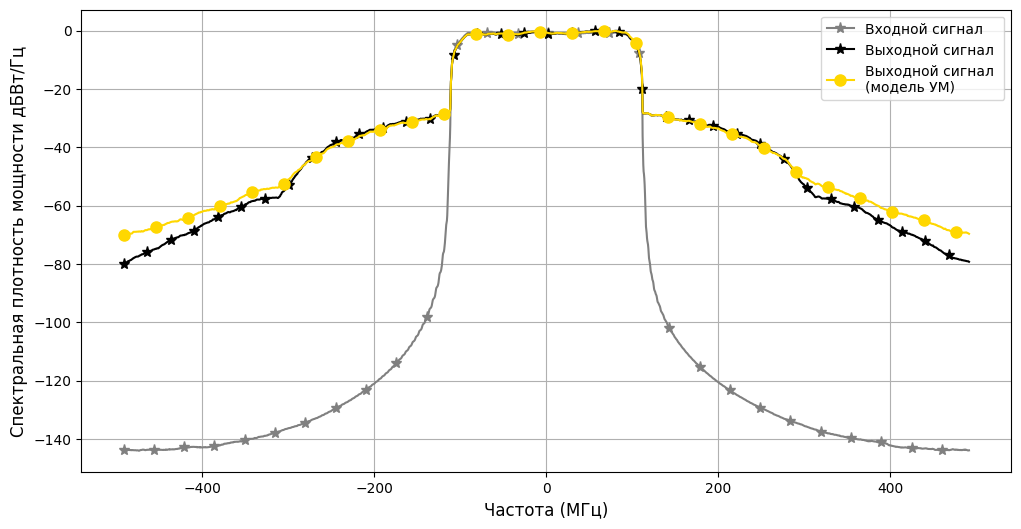

In [14]:
window_size = 50

freqs, spectrum_y_in = metrics.power_spectrum(container.val_input, container.input_signal_fs, container.nperseg, window_size)
_, spectrum_y_out = metrics.power_spectrum(container.val_output, container.input_signal_fs, container.nperseg, window_size)
_, spectrum_y_val_pa = metrics.power_spectrum(y_val_pa, container.input_signal_fs, container.nperseg, window_size)

xlabel="Частота (МГц)"
ylabel= "Спектральная плотность мощности дБВт/Гц"
fontsize = 12
figsize=(12, 6)
markersize=8

plt.figure(figsize=figsize)

plt.plot(freqs / 1e6, spectrum_y_in, color='grey', label='Входной сигнал', marker = '*', markevery=90, markersize=markersize)
plt.plot(freqs / 1e6, spectrum_y_out, color='black', label='Выходной сигнал', marker = '*', markevery=70, markersize=markersize)
plt.plot(freqs / 1e6, spectrum_y_val_pa, color='gold', label='Выходной сигнал \n(модель УМ)', marker='o', markevery=95, markersize=markersize)

plt.xlabel(xlabel, fontsize=fontsize)
plt.ylabel(ylabel, fontsize=fontsize)
# plt.ylim(bottom=-170)
# plt.xticks(np.arange(-500, 600, 100))
plt.legend()
plt.grid()
plt.show()


In [17]:
print(list(pa_model.parameters()))

[Parameter containing:
tensor([[ 1.5238+0.1150j,  1.3442-0.6183j],
        [-4.8373+2.9199j, -2.6001+1.6276j]]), Parameter containing:
tensor([[[ 1.5238+0.1150j,  1.5238+0.1150j],
         [ 1.3442-0.6183j,  1.3442-0.6183j]],

        [[-4.8373+2.9199j, -3.8945+4.2328j],
         [-2.6001+1.6276j,  1.9508+0.9241j]]]), Parameter containing:
tensor([[[ 1.5238+0.1150j,  1.3442-0.6183j],
         [ 1.3442-0.6183j, -1.3925+2.3183j]],

        [[-4.8373+2.9199j, -5.9224-0.3932j],
         [-2.6001+1.6276j, -1.8566-3.1425j]]])]
